In [144]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [145]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

In [172]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense,Dropout
from tensorflow.keras.optimizers import Adam

In [147]:
Dataset = r'C:\Users\USER\OneDrive\Desktop\Deep Learning\Deep Learning projects\Customer churn\WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(Dataset)

In [148]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [149]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [150]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [151]:
df.duplicated().sum()

np.int64(0)

In [152]:
df['gender'].value_counts()
df['MultipleLines'].value_counts()
df['PhoneService'].value_counts()
# df['InternetService'].value_counts() -----
# df['OnlineSecurity'].value_counts()
# df['OnlineBackup'].value_counts()
# df['DeviceProtection'].value_counts()
# df['TechSupport'].value_counts()
# df['StreamingTV'].value_counts()
# df['StreamingMovies'].value_counts()
# df['Contract'].value_counts()
# df['PaperlessBilling'].value_counts()
# df['PaymentMethod'].value_counts()  ----
# df['Churn'].value_counts()

df['TotalCharges'].value_counts()

TotalCharges
20.2      11
          11
19.75      9
19.9       8
20.05      8
          ..
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, Length: 6531, dtype: int64

In [153]:
LE = LabelEncoder()
df['gender'] = LE.fit_transform(df['gender'])
df['Partner'] = LE.fit_transform(df['Partner'])
df['Dependents'] = LE.fit_transform(df['Dependents'])
df['PhoneService'] = LE.fit_transform(df['PhoneService'])
df['PaperlessBilling'] = LE.fit_transform(df['PaperlessBilling'])
df['Churn'] = LE.fit_transform(df['Churn'])
df['MultipleLines'] = LE.fit_transform(df['MultipleLines'])
df['OnlineSecurity'] = LE.fit_transform(df['OnlineSecurity'])
df['OnlineBackup'] = LE.fit_transform(df['OnlineBackup'])
df['DeviceProtection'] = LE.fit_transform(df['DeviceProtection'])
df['TechSupport'] = LE.fit_transform(df['TechSupport'])
df['StreamingTV'] = LE.fit_transform(df['StreamingTV'])
df['StreamingMovies'] = LE.fit_transform(df['StreamingMovies'])
df['Contract'] = LE.fit_transform(df['Contract'])


In [154]:
df = pd.get_dummies(df, columns=['PaymentMethod', 'InternetService'], dtype=int)


In [155]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,...,MonthlyCharges,TotalCharges,Churn,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,7590-VHVEG,0,0,1,0,1,0,1,0,2,...,29.85,29.85,0,0,0,1,0,1,0,0
1,5575-GNVDE,1,0,0,0,34,1,0,2,0,...,56.95,1889.5,0,0,0,0,1,1,0,0
2,3668-QPYBK,1,0,0,0,2,1,0,2,2,...,53.85,108.15,1,0,0,0,1,1,0,0
3,7795-CFOCW,1,0,0,0,45,0,1,2,0,...,42.30,1840.75,0,1,0,0,0,1,0,0
4,9237-HQITU,0,0,0,0,2,1,0,0,0,...,70.70,151.65,1,0,0,1,0,0,1,0


In [156]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 26 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   customerID                               7043 non-null   str    
 1   gender                                   7043 non-null   int64  
 2   SeniorCitizen                            7043 non-null   int64  
 3   Partner                                  7043 non-null   int64  
 4   Dependents                               7043 non-null   int64  
 5   tenure                                   7043 non-null   int64  
 6   PhoneService                             7043 non-null   int64  
 7   MultipleLines                            7043 non-null   int64  
 8   OnlineSecurity                           7043 non-null   int64  
 9   OnlineBackup                             7043 non-null   int64  
 10  DeviceProtection                         7043 non-null   in

In [157]:
string_cols = df.select_dtypes(include=['object', 'string']).columns
print(string_cols)

Index(['customerID', 'TotalCharges'], dtype='str')


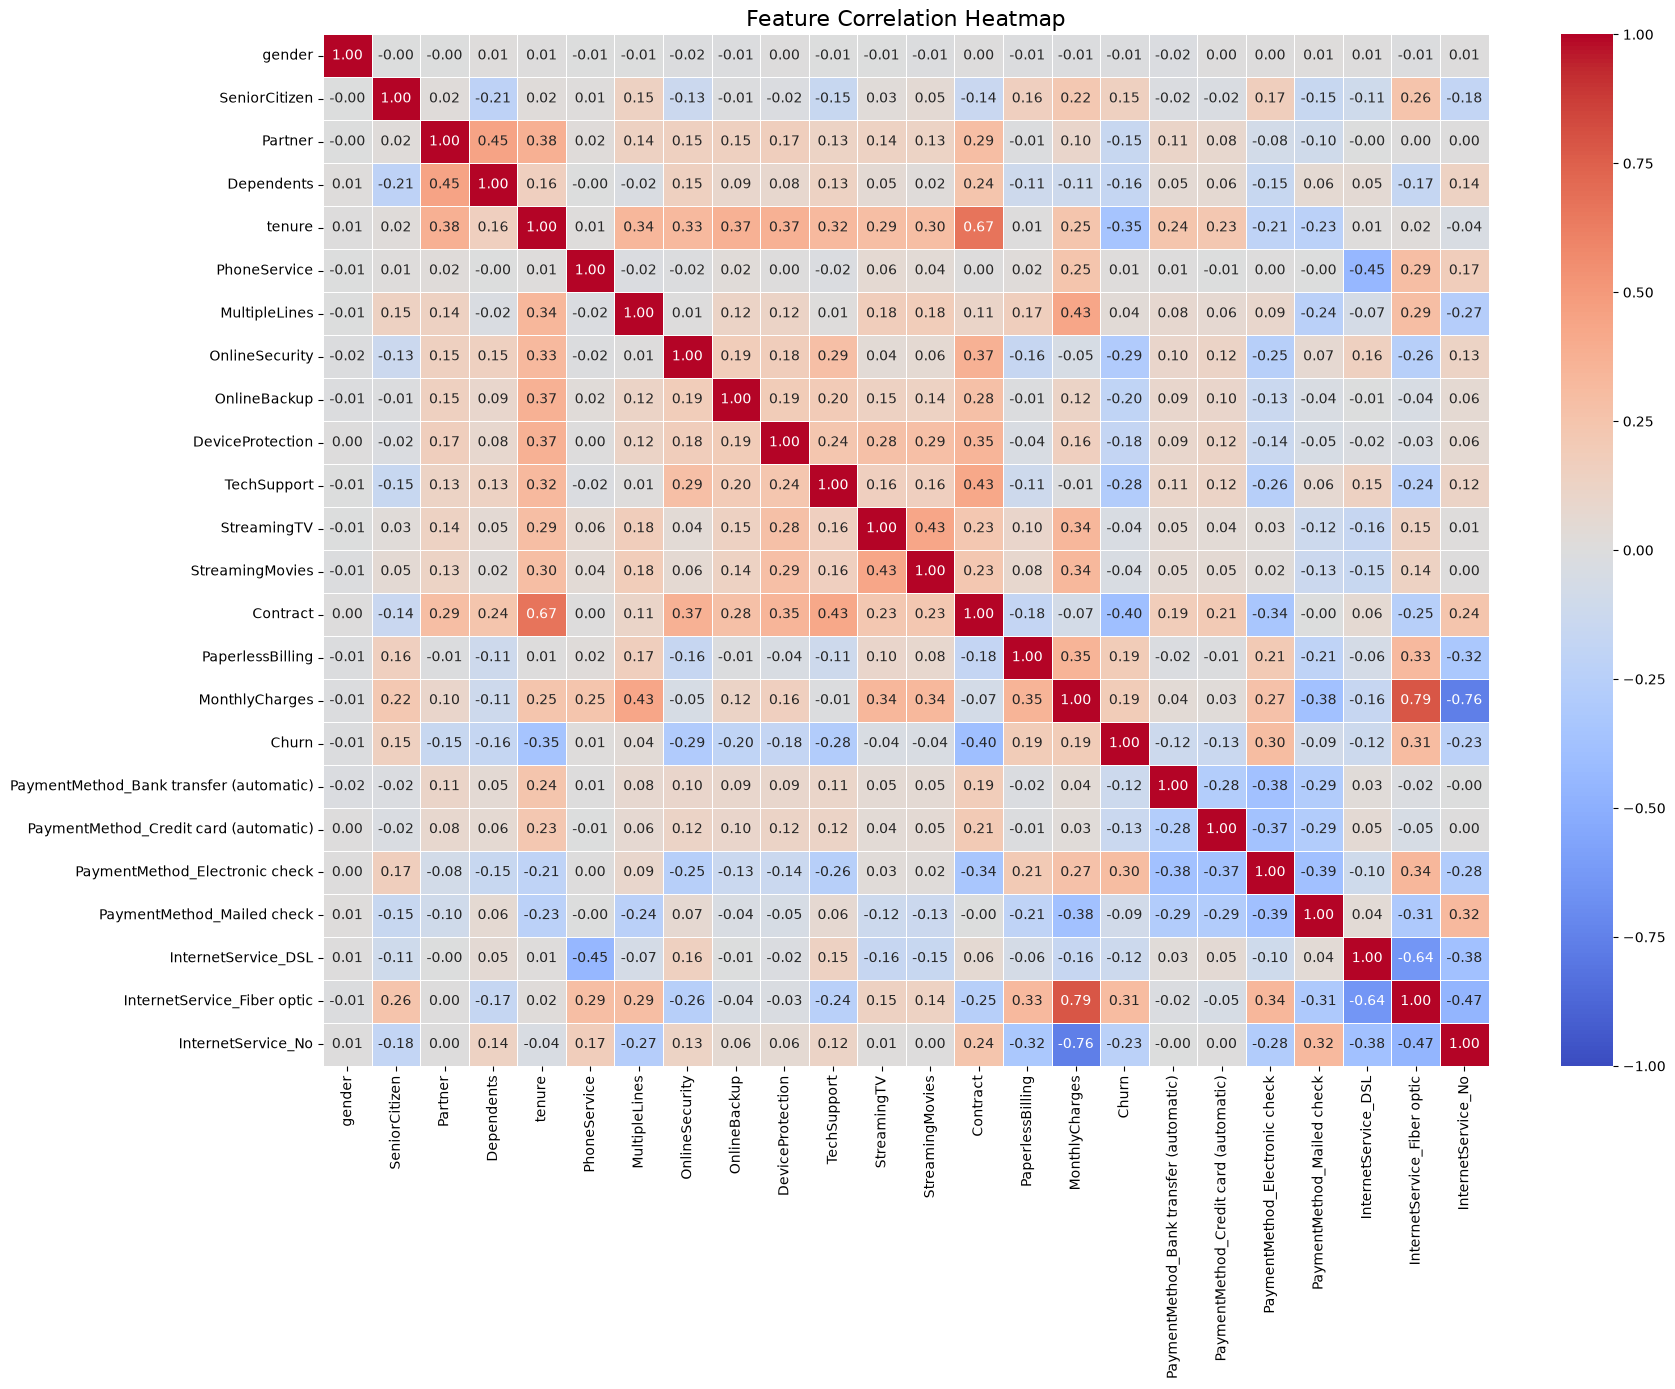

In [158]:

# 1. Calculate correlation matrix (numeric_only=True safely ignores text columns like customerID)
corr_matrix = df.corr(numeric_only=True)

# 2. Set figure size large enough for 25+ columns
plt.figure(figsize=(18, 14))

# 3. Plot the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,          # Show correlation numbers inside boxes
    fmt='.2f',           # Round numbers to 2 decimal places
    cmap='coolwarm',     # Blue for negative, Red for positive correlation
    vmin=-1, vmax=1,     # Fix color scale between -1 and 1
    linewidths=0.5       # Add thin lines between squares
)

plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()


In [159]:
X = df.drop(columns=['customerID','Churn','TotalCharges'])
y =df['Churn']

In [164]:
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [165]:
st = StandardScaler()
X_train = st.fit_transform(train_X)
X_test = st.transform(test_X)

In [166]:
X_train.shape

(5634, 23)

In [169]:
model = Sequential([
    layers.InputLayer(input_shape=(train_X.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu'),
    layers.Dense(2, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [171]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,329 (16.91 KB)

 Trainable params: 4,329 (16.91 KB)

 Non-trainable params: 0 (0.00 B)

In [173]:
adam = Adam(learning_rate=0.01)
model.compile(loss = 'binary_crossentropy',optimizer='adam' ,metrics=['accuracy'])

In [175]:
history = model.fit(X,y,epochs = 100,validation_split=0.2,verbose=1)

Epoch 1/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8030 - loss: 0.4204 - val_accuracy: 0.8013 - val_loss: 0.4383
Epoch 2/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8049 - loss: 0.4190 - val_accuracy: 0.7999 - val_loss: 0.4401
Epoch 3/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8021 - loss: 0.4177 - val_accuracy: 0.7871 - val_loss: 0.4399
Epoch 4/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8060 - loss: 0.4175 - val_accuracy: 0.7835 - val_loss: 0.4416
Epoch 5/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8024 - loss: 0.4203 - val_accuracy: 0.7942 - val_loss: 0.4336
Epoch 6/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8044 - loss: 0.4153 - val_accuracy: 0.7913 - val_loss: 0.4355
Epoch 7/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8033 - loss: 0.4171 - val_accuracy: 0.8006 - val_loss: 0.4370
Epoch 8/100
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8060 - loss: 0.4161 - val_accu

In [179]:
# Evaluate model on test data
loss, accuracy = model.evaluate(X, y)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8173 - loss: 0.3937
Test Loss: 0.3936980962753296
Test Accuracy: 81.72653913497925 %


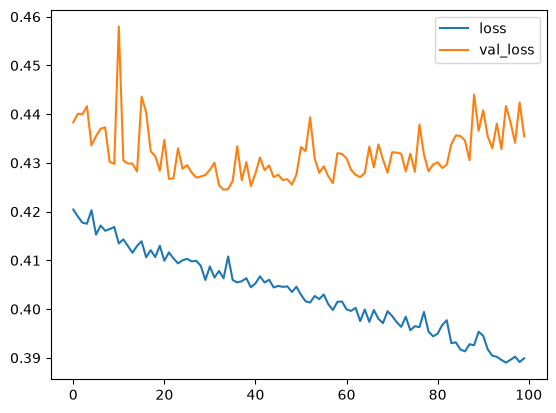

In [177]:
plt.plot(history.history['loss'],label = 'loss')
plt.plot(history.history['val_loss'],label = 'val_loss')
plt.legend()
plt.show()

In [182]:
# 1. Collect all 23 inputs dynamically using your training feature names (X.columns)
user_data = {}
print(f"Please enter values for the {len(X.columns)} features:\n")

for col in X.columns:
    val = float(input(f"Enter {col}: "))
    user_data[col] = val

# 2. Convert dictionary into a 1-row DataFrame with exact column order
input_df = pd.DataFrame([user_data], columns=X.columns)

# 3. Scale the input using the SAME scaler fitted on X_train
# (Skip this line ONLY if you did not use StandardScaler/MinMaxScaler during training)
input_scaled = st.transform(input_df)

# 4. Make prediction with your trained deep learning model
prediction_prob = model.predict(input_scaled)[0][0]
prediction_class = 1 if prediction_prob >= 0.5 else 0

print("\n--- Prediction Result ---")
print(f"Churn Probability: {prediction_prob:.2%}")
print(f"Predicted Churn: {'Yes (1)' if prediction_class == 1 else 'No (0)'}")


Please enter values for the 23 features:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step

--- Prediction Result ---
Churn Probability: 0.10%
Predicted Churn: No (0)
